**Variations on the Efficient Frontier**

1. Represent the efficient frontier by considering the following values of γ:
−1, −0.5, −0.25, 0, 0.25, 0.5, 1 and 2.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1: Define Portfolio Data (4 Assets)
# Expected returns
mu = np.array([0.05, 0.06, 0.08, 0.06])

# Volatilities
sigma = np.array([0.15, 0.20, 0.25, 0.30])

# Correlation matrix
C = np.array([
    [1.00, 0.10, 0.40, 0.50],
    [0.10, 1.00, 0.70, 0.40],
    [0.40, 0.70, 1.00, 0.80],
    [0.50, 0.40, 0.80, 1.00]
])

# Build covariance matrix: Sigma = D * C * D
D = np.diag(sigma)
Sigma = D @ C @ D

# Unit vector and inverse of Sigma
ones = np.ones(4)
inv_Sigma = np.linalg.inv(Sigma)

# 2: Precompute Analytical Constants
# A = 1^T * Sigma^{-1} * 1
A = ones @ inv_Sigma @ ones
# B = 1^T * Sigma^{-1} * mu
B = ones @ inv_Sigma @ mu

In [2]:
# 3: Solve for Each Specified Gamma Value
gamma_values = [-1, -0.5, -0.25, 0, 0.25, 0.5, 1, 2]
results = []

print("=" * 85)
print("Efficient Frontier for Different Gamma Values")
print("=" * 85)
print(f"{'gamma':>8} | {'x1*':>8} | {'x2*':>8} | {'x3*':>8} | {'x4*':>8} | "
      f"{'mu(x*)':>8} | {'sigma(x*)':>10}")
print("-" * 85)

for gamma in gamma_values:
    # Analytical solution via Largrangian:
    # x*(gamma) = (1/A)*inv(Sigma)*1 + gamma*[inv(Sigma)*mu - (B/A)*inv(Sigma)*1]
    x_opt = (1.0 / A) * (inv_Sigma @ ones) + \
            gamma * (inv_Sigma @ mu - (B / A) * (inv_Sigma @ ones))

    # Compute portfolio expected return and volatility
    port_return = mu @ x_opt
    port_vol = np.sqrt(x_opt @ Sigma @ x_opt)

    results.append((gamma, x_opt, port_return, port_vol))

    print(f"{gamma:8.2f} | {x_opt[0]*100:7.2f}% | {x_opt[1]*100:7.2f}% | "
          f"{x_opt[2]*100:7.2f}% | {x_opt[3]*100:7.2f}% | "
          f"{port_return*100:7.2f}% | {port_vol*100:9.2f}%")

print("-" * 85)

Efficient Frontier for Different Gamma Values
   gamma |      x1* |      x2* |      x3* |      x4* |   mu(x*) |  sigma(x*)
-------------------------------------------------------------------------------------
   -1.00 |   94.04% |  120.05% | -185.79% |   71.69% |    1.34% |     22.27%
   -0.50 |   83.39% |   84.76% | -103.12% |   34.97% |    3.10% |     15.23%
   -0.25 |   78.07% |   67.11% |  -61.79% |   16.61% |    3.98% |     12.88%
    0.00 |   72.74% |   49.46% |  -20.45% |   -1.75% |    4.86% |     12.00%
    0.25 |   67.42% |   31.82% |   20.88% |  -20.12% |    5.74% |     12.88%
    0.50 |   62.09% |   14.17% |   62.21% |  -38.48% |    6.62% |     15.23%
    1.00 |   51.44% |  -21.13% |  144.88% |  -75.20% |    8.38% |     22.27%
    2.00 |   30.15% |  -91.72% |  310.22% | -148.65% |   11.90% |     39.39%
-------------------------------------------------------------------------------------


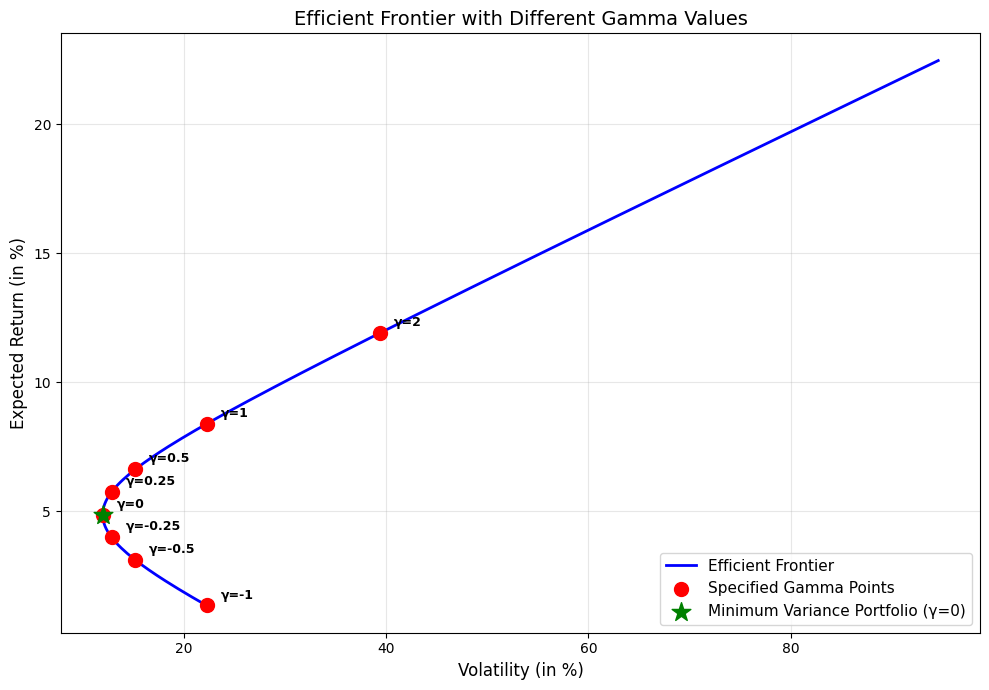

In [3]:
# 4: Plot the Efficient Frontier

plt.figure(figsize=(10, 7))

# Plot smooth efficient frontier using a dense range of gamma
gamma_dense = np.linspace(-1, 5, 200)
frontier_vols = []
frontier_returns = []

for g in gamma_dense:
    x_opt = (1.0 / A) * (inv_Sigma @ ones) + \
            g * (inv_Sigma @ mu - (B / A) * (inv_Sigma @ ones))
    frontier_returns.append((mu @ x_opt) * 100)
    frontier_vols.append(np.sqrt(x_opt @ Sigma @ x_opt) * 100)

plt.plot(frontier_vols, frontier_returns, 'b-', linewidth=2,
         label='Efficient Frontier')

# Highlight the specified gamma points
q_vols = [r[3] * 100 for r in results]
q_returns = [r[2] * 100 for r in results]
plt.scatter(q_vols, q_returns, color='red', s=100, zorder=5,
            label='Specified Gamma Points')

# Annotate each point with its gamma value
for gamma, _, ret, vol in results:
    plt.annotate(f'γ={gamma}', (vol * 100, ret * 100),
                 textcoords="offset points", xytext=(10, 5),
                 fontsize=9, fontweight='bold')

# Mark the Minimum Variance Portfolio (gamma = 0)
mvp_idx = gamma_values.index(0)
plt.scatter(q_vols[mvp_idx], q_returns[mvp_idx], color='green', s=200,
            marker='*', zorder=6, label='Minimum Variance Portfolio (γ=0)')

# Formatting
plt.xlabel('Volatility (in %)', fontsize=12)
plt.ylabel('Expected Return (in %)', fontsize=12)
plt.title('Efficient Frontier with Different Gamma Values', fontsize=14)
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

2. Calculate the minimum variance portfolio. What are its expected return and its volatility?

In [4]:
# ============================================================
# Question: Calculate the Minimum Variance Portfolio (MVP)
# ============================================================
# The MVP corresponds to gamma = 0 in the gamma-problem.
# When gamma = 0, the analytical solution simplifies to:
#   x_mvp = (1/A) * Sigma^{-1} * 1
# It depends only on the covariance matrix, not on expected returns.

x_mvp = (1.0 / A) * (inv_Sigma @ ones)

# Calculate expected return and volatility
mvp_return = mu @ x_mvp
mvp_volatility = np.sqrt(x_mvp @ Sigma @ x_mvp)

# Print Results
print("\n" + "=" * 60)
print("Minimum Variance Portfolio (MVP)")
print("=" * 60)
print(f"Constant A = 1^T * Sigma^{-1} * 1 : {A:.4f}")
print(f"Constant B = 1^T * Sigma^{-1} * mu: {B:.4f}\n")

print("Optimal Weights:")
for i in range(4):
    print(f"  x{i+1} = {x_mvp[i]*100:7.2f}%")

print(f"\nSum of weights: {np.sum(x_mvp)*100:.2f}% (budget constraint satisfied)")

print("\n" + "-" * 60)
print(f"Expected Return  mu(x_mvp)    = {mvp_return*100:.2f}%")
print(f"Volatility       sigma(x_mvp) = {mvp_volatility*100:.2f}%")
print("-" * 60)


Minimum Variance Portfolio (MVP)
Constant A = 1^T * Sigma^-1 * 1 : 69.5000
Constant B = 1^T * Sigma^-1 * mu: 3.3801

Optimal Weights:
  x1 =   72.74%
  x2 =   49.46%
  x3 =  -20.45%
  x4 =   -1.75%

Sum of weights: 100.00% (budget constraint satisfied)

------------------------------------------------------------
Expected Return  mu(x_mvp)    = 4.86%
Volatility       sigma(x_mvp) = 12.00%
------------------------------------------------------------


3. Calculate the optimal portfolio which has an ex-ante volatility σ? equal to 10%. Same question if σ? = 15% and σ? = 20%.

In [5]:
# ============================================================
# Question: Optimal Portfolios for Target Ex-Ante Volatilities
# ============================================================
# For the gamma-problem, the relationship between ex-ante variance and gamma is:
#   sigma^2(gamma) = (1/A) + gamma^2 * (D_scalar / A)
# where D_scalar = A*C_scalar - B^2 and C_scalar = mu^T * Sigma^{-1} * mu
#
# Solving for gamma from a target sigma*:
#   gamma = sqrt( (A * sigma*^2 - 1) / D_scalar )

# Precompute the remaining analytical constants
C_scalar = mu @ inv_Sigma @ mu
D_scalar = A * C_scalar - B**2

# Target volatilities
target_vols = [0.10, 0.15, 0.20]

print("\n" + "=" * 85)
print("Optimal Portfolios for Target Ex-Ante Volatilities")
print("=" * 85)
print(f"{'sigma*':>8} | {'gamma':>8} | {'x1*':>8} | {'x2*':>8} | {'x3*':>8} | {'x4*':>8} | "
      f"{'mu(x*)':>8} | {'phi':>8}")
print("-" * 85)

for sigma_star in target_vols:
    # Solve for gamma analytically from the target volatility
    gamma = np.sqrt((A * (sigma_star**2) - 1) / D_scalar)

    # Calculate optimal weights using the Lagrangian analytical solution
    x_opt = (1.0 / A) * (inv_Sigma @ ones) + \
            gamma * (inv_Sigma @ mu - (B / A) * (inv_Sigma @ ones))

    # Calculate ex-ante expected return and risk aversion parameter phi
    port_return = mu @ x_opt
    phi = 1.0 / gamma

    print(f"{sigma_star*100:7.2f}% | {gamma:8.4f} | {x_opt[0]*100:7.2f}% | {x_opt[1]*100:7.2f}% | "
          f"{x_opt[2]*100:7.2f}% | {x_opt[3]*100:7.2f}% | {port_return*100:7.2f}% | {phi:8.4f}")

print("-" * 85)


Optimal Portfolios for Target Ex-Ante Volatilities
  sigma* |    gamma |      x1* |      x2* |      x3* |      x4* |   mu(x*) |      phi
-------------------------------------------------------------------------------------
  10.00% |      nan |     nan% |     nan% |     nan% |     nan% |     nan% |      nan
  15.00% |   0.4801 |   62.52% |   15.58% |   58.92% |  -37.01% |    6.55% |   2.0831
  20.00% |   0.8530 |   54.57% |  -10.75% |  120.58% |  -64.41% |    7.87% |   1.1723
-------------------------------------------------------------------------------------


C:\Users\dengyikai\AppData\Local\Temp\ipykernel_14224\50997699.py:27: RuntimeWarning: invalid value encountered in sqrt
  gamma = np.sqrt((A * (sigma_star**2) - 1) / D_scalar)


4. We note x(1) the minimum variance portfolio and x(2) the optimal portfolio with σ? = 20%. We consider the set of portfolios x(α) defined by
the relationship:
x(α) = (1 − α) x(1) + αx(2)
In the previous efficient frontier, place the portfolios x(α) when α is equal to −0.5, −0.25, 0, 0.1, 0.2, 0.5, 0.7 and 1.


Two-Fund Separation: Constructed Portfolios x^(alpha)
   alpha |      x1* |      x2* |      x3* |      x4* |   mu(x*) |  sigma(x*)
-------------------------------------------------------------------------------------
   -0.50 |   81.83% |   79.57% |  -90.97% |   29.57% |    3.36% |     14.42%
   -0.25 |   77.28% |   64.52% |  -55.71% |   13.91% |    4.11% |     12.64%
    0.00 |   72.74% |   49.46% |  -20.45% |   -1.75% |    4.86% |     12.00%
    0.10 |   70.93% |   43.44% |   -6.35% |   -8.02% |    5.16% |     12.10%
    0.20 |   69.11% |   37.42% |    7.75% |  -14.28% |    5.46% |     12.41%
    0.50 |   63.66% |   19.36% |   50.06% |  -33.08% |    6.36% |     14.42%
    0.70 |   60.03% |    7.31% |   78.27% |  -45.61% |    6.97% |     16.41%
    1.00 |   54.57% |  -10.75% |  120.58% |  -64.41% |    7.87% |     20.00%
-------------------------------------------------------------------------------------


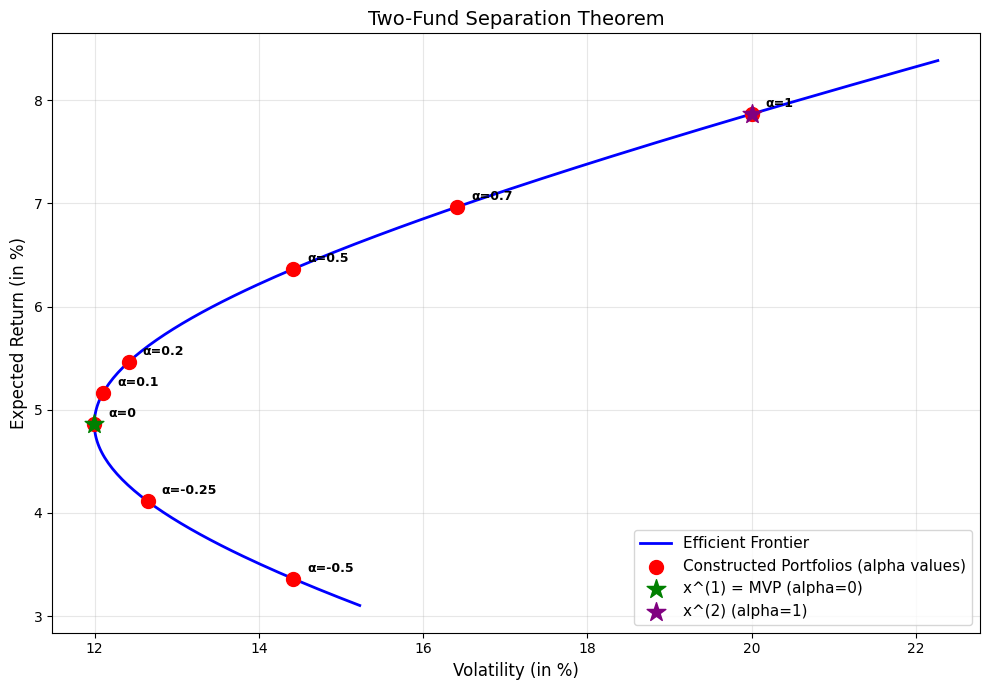

In [6]:
# ============================================================
# Question: Two-Fund Separation
# ============================================================
# x^(1) is the Minimum Variance Portfolio (gamma = 0)
# x^(2) is the optimal portfolio for sigma* = 20%

# --- Portfolio x^(1): MVP (gamma = 0) ---
x1 = (1.0 / A) * (inv_Sigma @ ones)

# --- Portfolio x^(2): Optimal for sigma* = 20% ---
# We reuse the analytical constants from the previous question
sigma_star_2 = 0.20
gamma_2 = np.sqrt((A * (sigma_star_2**2) - 1) / D_scalar)
x2 = (1.0 / A) * (inv_Sigma @ ones) + \
     gamma_2 * (inv_Sigma @ mu - (B / A) * (inv_Sigma @ ones))

# Alpha values to evaluate
alpha_values = [-0.5, -0.25, 0, 0.1, 0.2, 0.5, 0.7, 1]

# Store results for printing and plotting
q4_results = []

print("\n" + "=" * 85)
print("Two-Fund Separation: Constructed Portfolios x^(alpha)")
print("=" * 85)
print(f"{'alpha':>8} | {'x1*':>8} | {'x2*':>8} | {'x3*':>8} | {'x4*':>8} | "
      f"{'mu(x*)':>8} | {'sigma(x*)':>10}")
print("-" * 85)

for alpha in alpha_values:
    # Construct portfolio x^(alpha) as a linear combination of x1 and x2
    x_alpha = (1 - alpha) * x1 + alpha * x2

    # Calculate ex-ante expected return and volatility
    port_return = mu @ x_alpha
    port_vol = np.sqrt(x_alpha @ Sigma @ x_alpha)

    q4_results.append((alpha, x_alpha, port_return, port_vol))

    print(f"{alpha:8.2f} | {x_alpha[0]*100:7.2f}% | {x_alpha[1]*100:7.2f}% | "
          f"{x_alpha[2]*100:7.2f}% | {x_alpha[3]*100:7.2f}% | "
          f"{port_return*100:7.2f}% | {port_vol*100:9.2f}%")

print("-" * 85)

# ============================================================
# Plotting the Results
# ============================================================
plt.figure(figsize=(10, 7))

# Plot the theoretical efficient frontier (dense gamma range)
gamma_dense = np.linspace(-0.5, 1.0, 200)
frontier_vols = []
frontier_returns = []
for g in gamma_dense:
    x_opt = (1.0 / A) * (inv_Sigma @ ones) + \
            g * (inv_Sigma @ mu - (B / A) * (inv_Sigma @ ones))
    frontier_returns.append((mu @ x_opt) * 100)
    frontier_vols.append(np.sqrt(x_opt @ Sigma @ x_opt) * 100)

plt.plot(frontier_vols, frontier_returns, 'b-', linewidth=2,
         label='Efficient Frontier')

# Plot the Q4 constructed portfolios
q4_vols = [r[3] * 100 for r in q4_results]
q4_returns = [r[2] * 100 for r in q4_results]
plt.scatter(q4_vols, q4_returns, color='red', s=100, zorder=5,
            label='Constructed Portfolios (alpha values)')

# Annotate each point with its alpha value
for alpha, _, ret, vol in q4_results:
    plt.annotate(f'α={alpha}', (vol * 100, ret * 100),
                 textcoords="offset points", xytext=(10, 5),
                 fontsize=9, fontweight='bold')

# Mark x^(1) and x^(2) for clarity
plt.scatter(q4_vols[2], q4_returns[2], color='green', s=200,
            marker='*', zorder=6, label='x^(1) = MVP (alpha=0)')
plt.scatter(q4_vols[-1], q4_returns[-1], color='purple', s=200,
            marker='*', zorder=6, label='x^(2) (alpha=1)')

# Formatting
plt.xlabel('Volatility (in %)', fontsize=12)
plt.ylabel('Expected Return (in %)', fontsize=12)
plt.title('Two-Fund Separation Theorem', fontsize=14)
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

5. Repeat Questions 3 and 4 by considering the constraint 0 ≤ xi ≤ 1.


Q3 (Constrained 0 <= xi <= 1): Optimal Portfolios for Target Volatilities
Constrained MVP volatility: 12.56%  (vs. unconstrained: 12.00%)
  sigma* |    gamma |      x1* |      x2* |      x3* |      x4* |   mu(x*)
-------------------------------------------------------------------------------------
  10.00% |    NaN   |    --- Infeasible: sigma* < sigma_mvp_c (12.56%) ---
  15.00% |   0.6595 |   45.31% |   25.16% |   29.53% |    0.00% |    6.14%
  20.00% |   1.1015 |   24.88% |    4.96% |   70.15% |    0.00% |    7.15%
-------------------------------------------------------------------------------------

Q4 (Constrained): Two-Fund Separation Test
 alpha |      x1* |      x2* |      x3* |      x4* |   mu(x*) |  sigma(x*) | In Bounds?
-----------------------------------------------------------------------------------------------
 -0.50 |   85.79% |   49.29% |  -35.08% |   -0.00% |    4.44% |     12.40% | NO (violated)
 -0.25 |   75.64% |   41.90% |  -17.54% |   -0.00% |    4.89% |     12

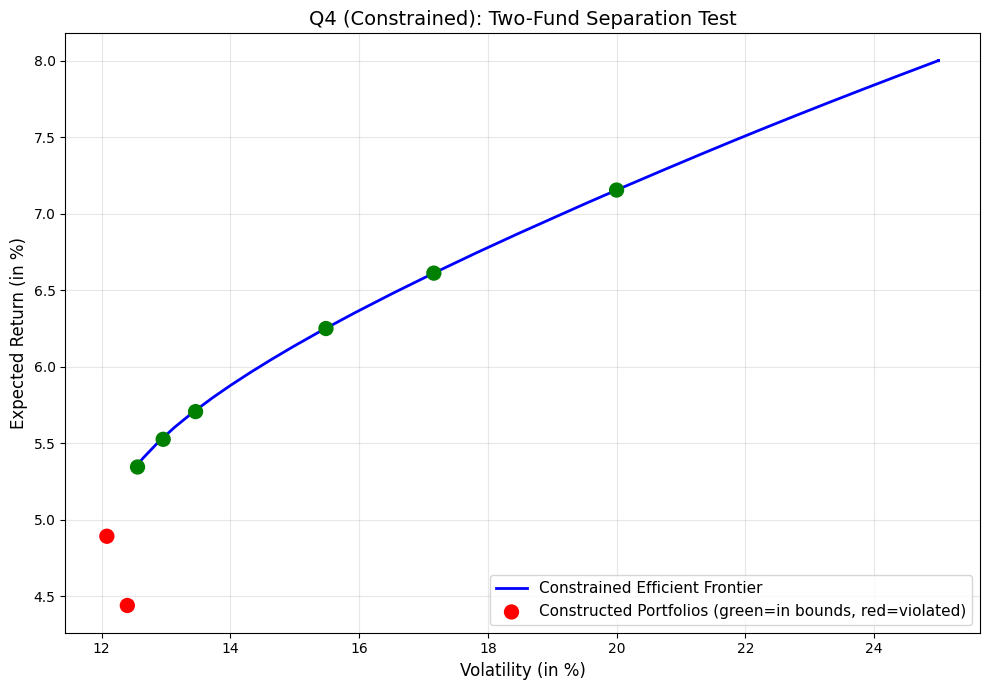

In [7]:
from scipy.optimize import minimize

# ============================================================
# Questions 3 & 4 with Constraint: 0 <= xi <= 1 (Long-Only, No Leverage)
# ============================================================
# When inequality constraints are active, the analytical Lagrangian
# solution FAILS. We must use numerical optimization (SLSQP) + bisection.

# Define the objective function for the gamma-problem
def objective(x, gamma):
    return 0.5 * x.T @ Sigma @ x - gamma * x.T @ mu

# Function to solve the QP for a given gamma with specific bounds
def solve_constrained(gamma, bounds):
    cons = {'type': 'eq', 'fun': lambda x: np.sum(x) - 1}
    x0 = np.array([0.25, 0.25, 0.25, 0.25])
    res = minimize(objective, x0, args=(gamma,), method='SLSQP',
                   bounds=bounds, constraints=cons)
    return res.x

# Bisection algorithm to find gamma for a target volatility
def find_gamma_for_sigma(sigma_target, bounds, gamma_max=100.0):
    gamma_low, gamma_high = 0.0, gamma_max
    for _ in range(100):
        gamma_mid = (gamma_low + gamma_high) / 2.0
        x_opt = solve_constrained(gamma_mid, bounds)
        vol = np.sqrt(x_opt @ Sigma @ x_opt)
        if abs(vol - sigma_target) < 1e-6:
            break
        if vol < sigma_target:
            gamma_low = gamma_mid
        else:
            gamma_high = gamma_mid
    return gamma_mid, x_opt

# Define bounds: 0 <= xi <= 1
bounds = [(0, 1) for _ in range(4)]

# --- Compute the CONSTRAINED MVP (gamma = 0) ---
x_mvp_c = solve_constrained(0.0, bounds)
sigma_mvp_c = np.sqrt(x_mvp_c @ Sigma @ x_mvp_c)
mu_mvp_c = mu @ x_mvp_c

print("\n" + "=" * 85)
print("Q3 (Constrained 0 <= xi <= 1): Optimal Portfolios for Target Volatilities")
print(f"Constrained MVP volatility: {sigma_mvp_c*100:.2f}%  (vs. unconstrained: 12.00%)")
print("=" * 85)
print(f"{'sigma*':>8} | {'gamma':>8} | {'x1*':>8} | {'x2*':>8} | {'x3*':>8} | {'x4*':>8} | {'mu(x*)':>8}")
print("-" * 85)

# --- Q3: Solve for each target volatility ---
target_vols = [0.10, 0.15, 0.20]
q3_constrained = []

for sigma_star in target_vols:
    if sigma_star < sigma_mvp_c:
        print(f"{sigma_star*100:7.2f}% |    NaN   |    --- Infeasible: sigma* < sigma_mvp_c ({sigma_mvp_c*100:.2f}%) ---")
        q3_constrained.append((sigma_star, None, None, None))
        continue
    gamma, x_opt = find_gamma_for_sigma(sigma_star, bounds)
    port_return = mu @ x_opt
    q3_constrained.append((sigma_star, gamma, x_opt, port_return))
    print(f"{sigma_star*100:7.2f}% | {gamma:8.4f} | {x_opt[0]*100:7.2f}% | {x_opt[1]*100:7.2f}% | "
          f"{x_opt[2]*100:7.2f}% | {x_opt[3]*100:7.2f}% | {port_return*100:7.2f}%")
print("-" * 85)

# --- Q4: Two-Fund Separation with constraints ---
# x^(1) = constrained MVP, x^(2) = constrained optimal for sigma* = 20%
x1_c = x_mvp_c
x2_c = q3_constrained[-1][2]  # sigma* = 20%

alpha_values = [-0.5, -0.25, 0, 0.1, 0.2, 0.5, 0.7, 1]
q4_constrained = []

print("\n" + "=" * 95)
print("Q4 (Constrained): Two-Fund Separation Test")
print("=" * 95)
print(f"{'alpha':>6} | {'x1*':>8} | {'x2*':>8} | {'x3*':>8} | {'x4*':>8} | "
      f"{'mu(x*)':>8} | {'sigma(x*)':>10} | {'In Bounds?':>10}")
print("-" * 95)

for alpha in alpha_values:
    x_alpha = (1 - alpha) * x1_c + alpha * x2_c
    port_return = mu @ x_alpha
    port_vol = np.sqrt(x_alpha @ Sigma @ x_alpha)
    in_bounds = np.all((x_alpha >= -1e-6) & (x_alpha <= 1 + 1e-6))
    q4_constrained.append((alpha, x_alpha, port_return, port_vol, in_bounds))
    bound_str = "YES" if in_bounds else "NO (violated)"
    print(f"{alpha:6.2f} | {x_alpha[0]*100:7.2f}% | {x_alpha[1]*100:7.2f}% | "
          f"{x_alpha[2]*100:7.2f}% | {x_alpha[3]*100:7.2f}% | "
          f"{port_return*100:7.2f}% | {port_vol*100:9.2f}% | {bound_str:>10}")
print("-" * 95)

# --- Plot the constrained efficient frontier and Q4 points ---
plt.figure(figsize=(10, 7))

# Trace the constrained efficient frontier numerically
gamma_range = np.linspace(0, 5, 100)
cfront_vols = []
cfront_returns = []
for g in gamma_range:
    x_opt = solve_constrained(g, bounds)
    cfront_returns.append((mu @ x_opt) * 100)
    cfront_vols.append(np.sqrt(x_opt @ Sigma @ x_opt) * 100)

plt.plot(cfront_vols, cfront_returns, 'b-', linewidth=2,
         label='Constrained Efficient Frontier')

# Plot Q4 constructed portfolios
q4_vols = [r[3] * 100 for r in q4_constrained]
q4_returns = [r[2] * 100 for r in q4_constrained]
colors = ['green' if r[4] else 'red' for r in q4_constrained]
plt.scatter(q4_vols, q4_returns, c=colors, s=100, zorder=5,
            label='Constructed Portfolios (green=in bounds, red=violated)')

for alpha, _, ret, vol, _ in q4_constrained:
    plt.annotate(f'α={alpha}', (vol, ret),
                 textcoords="offset points", xytext=(10, 5),
                 fontsize=9, fontweight='bold')

plt.xlabel('Volatility (in %)', fontsize=12)
plt.ylabel('Expected Return (in %)', fontsize=12)
plt.title('Q4 (Constrained): Two-Fund Separation Test', fontsize=14)
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

6. We now include in the investment universe a fifth asset corresponding to the risk-free asset. Its return is equal to 3%.<br>
<br>a. Define the expected return vector and the covariance matrix of asset returns<br>
b. Deduce the efficient frontier by solving directly the quadratic problem.

In [8]:
# ============================================================
# Question: Include the Risk-Free Asset (5th Asset)
# ============================================================
# The risk-free asset has:
#   - Return r = 3%
#   - Volatility = 0
#   - Covariance with all risky assets = 0
#   - Variance = 0

# Risk-free rate
r = 0.03

# --- Augmented expected return vector (5x1) ---
# mu_tilde = [mu_1, mu_2, mu_3, mu_4, r]
mu_tilde = np.append(mu, r)

# --- Augmented covariance matrix (5x5) ---
# Sigma_tilde = [[Sigma, 0], [0^T, 0]]
# The risk-free asset has zero variance and zero covariance with all risky assets
Sigma_tilde = np.zeros((5, 5))
Sigma_tilde[:4, :4] = Sigma  # Top-left 4x4 block: original covariance matrix
# The 5th row and 5th column remain zeros (risk-free asset properties)

# Display the augmented parameters
print("=" * 70)
print("Augmented Investment Universe (with Risk-Free Asset)")
print("=" * 70)

print("\nAugmented Expected Return Vector mu_tilde:")
for i in range(5):
    asset_name = f"Asset {i+1} (Risky)" if i < 4 else "Asset 5 (Risk-Free)"
    print(f"  mu_tilde[{i+1}] = {mu_tilde[i]*100:6.2f}%   ({asset_name})")

print("\nAugmented Covariance Matrix Sigma_tilde:")
print("           Asset 1   Asset 2   Asset 3   Asset 4   Asset 5(RF)")
for i in range(5):
    row_label = f"Asset {i+1}" + ("(RF)" if i == 4 else "   ")
    row_str = "  ".join(f"{Sigma_tilde[i,j]*100:8.2f}" for j in range(5))
    print(f"  {row_label}  {row_str}")

# Verification: properties of the risk-free asset
print("\n" + "-" * 70)
print("Verification of Risk-Free Asset Properties:")
print(f"  Variance of Asset 5       : {Sigma_tilde[4,4]:.4f}  (should be 0)")
print(f"  Cov(RF, Asset 1)          : {Sigma_tilde[0,4]:.4f}  (should be 0)")
print(f"  Cov(RF, Asset 2)          : {Sigma_tilde[1,4]:.4f}  (should be 0)")
print(f"  Cov(RF, Asset 3)          : {Sigma_tilde[2,4]:.4f}  (should be 0)")
print(f"  Cov(RF, Asset 4)          : {Sigma_tilde[3,4]:.4f}  (should be 0)")
print(f"  Return of Asset 5         : {mu_tilde[4]*100:.2f}%  (should be 3%)")
print("-" * 70)

Augmented Investment Universe (with Risk-Free Asset)

Augmented Expected Return Vector mu_tilde:
  mu_tilde[1] =   5.00%   (Asset 1 (Risky))
  mu_tilde[2] =   6.00%   (Asset 2 (Risky))
  mu_tilde[3] =   8.00%   (Asset 3 (Risky))
  mu_tilde[4] =   6.00%   (Asset 4 (Risky))
  mu_tilde[5] =   3.00%   (Asset 5 (Risk-Free))

Augmented Covariance Matrix Sigma_tilde:
           Asset 1   Asset 2   Asset 3   Asset 4   Asset 5(RF)
  Asset 1         2.25      0.30      1.50      2.25      0.00
  Asset 2         0.30      4.00      3.50      2.40      0.00
  Asset 3         1.50      3.50      6.25      6.00      0.00
  Asset 4         2.25      2.40      6.00      9.00      0.00
  Asset 5(RF)      0.00      0.00      0.00      0.00      0.00

----------------------------------------------------------------------
Verification of Risk-Free Asset Properties:
  Variance of Asset 5       : 0.0000  (should be 0)
  Cov(RF, Asset 1)          : 0.0000  (should be 0)
  Cov(RF, Asset 2)          : 0.0000  

Tangency Portfolio (Analytical Solution)
Risk-free rate r            : 3.00%
Sharpe Ratio (slope of CML) : 0.2436
  (= sqrt(delta^T Sigma^-1 delta))

Tangency Portfolio Weights (risky assets only):
  x1 =   56.30%
  x2 =   -5.04%
  x3 =  107.21%
  x4 =  -58.46%
  Sum  =  100.00%

Tangency Portfolio Metrics:
  Expected Return mu_tan    : 7.58%
  Volatility sigma_tan      : 18.81%
  Sharpe Ratio              : 0.2436
----------------------------------------------------------------------


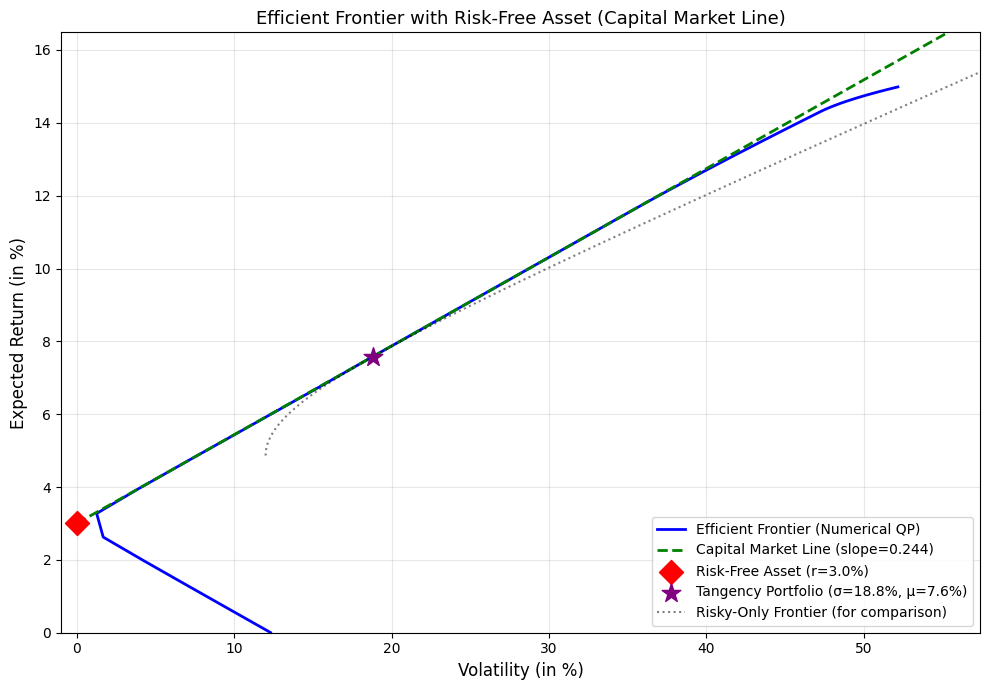


Verification: The Efficient Frontier is a Straight Line (CML)
   gamma |    sigma_p |       mu_p |   mu_p (CML) |       Diff
----------------------------------------------------------------------
    0.00 |      0.72% |      2.92% |        3.18% |    0.2562%
    0.50 |     12.51% |      6.04% |        6.05% |    0.0057%
    1.00 |     24.34% |      8.93% |        8.93% |    0.0000%
    1.50 |     35.98% |     11.76% |       11.76% |    0.0016%
    2.00 |     44.09% |     13.62% |       13.74% |    0.1214%
    3.00 |     48.29% |     14.50% |       14.76% |    0.2645%
----------------------------------------------------------------------
The near-zero differences confirm that the efficient frontier is the CML:
  mu_p = r + Sharpe * sigma_p  =  3.00% + 0.2436 * sigma_p


In [9]:
from scipy.optimize import minimize

# ============================================================
# Question: Efficient Frontier with Risk-Free Asset (Direct QP)
# ============================================================
# The augmented problem is:
#   min  (1/2) * x_tilde^T * Sigma_tilde * x_tilde - gamma * x_tilde^T * mu_tilde
#   s.t. 1^T x_tilde = 1
#
# Note: Sigma_tilde is SINGULAR (rank 4), so we cannot use the analytical
# Lagrangian formula with inv(Sigma_tilde). We solve it numerically instead.

# Define the augmented objective function
def augmented_objective(x_tilde, gamma):
    return 0.5 * x_tilde @ Sigma_tilde @ x_tilde - gamma * x_tilde @ mu_tilde

# Solve the augmented QP for a given gamma
def solve_augmented_qp(gamma):
    cons = {'type': 'eq', 'fun': lambda x: np.sum(x) - 1}
    x0 = np.array([0.2, 0.2, 0.2, 0.2, 0.2])
    # Bounds: allow short-selling (unconstrained), but keep weights finite
    bounds = [(-2, 2) for _ in range(5)]
    res = minimize(augmented_objective, x0, args=(gamma,),
                   method='SLSQP', bounds=bounds, constraints=cons)
    return res.x

# --- Solve for a range of gamma values ---
gamma_range = np.linspace(-0.5, 5, 50)
augmented_vols = []
augmented_returns = []
augmented_weights = []

for g in gamma_range:
    x_tilde = solve_augmented_qp(g)
    # Compute portfolio metrics
    port_return = x_tilde @ mu_tilde
    # Variance only comes from risky assets (rf asset has 0 variance)
    port_vol = np.sqrt(x_tilde @ Sigma_tilde @ x_tilde)
    augmented_returns.append(port_return * 100)
    augmented_vols.append(port_vol * 100)
    augmented_weights.append(x_tilde)

# --- Analytical verification: Capital Market Line (CML) ---
# The optimal risky-asset allocation is: x* = gamma * Sigma^{-1} * (mu - r*1)
# The CML equation is: mu_p = r + Sharpe_tangency * sigma_p
# where Sharpe_tangency = sqrt( (mu - r*1)^T * Sigma^{-1} * (mu - r*1) )

delta = mu - r * ones  # Excess returns vector
sharpe_tangency_sq = delta @ inv_Sigma @ delta
sharpe_tangency = np.sqrt(sharpe_tangency_sq)

# Tangency portfolio (unnormalized, then normalized to sum to 1)
x_tangency_unnorm = inv_Sigma @ delta
x_tangency = x_tangency_unnorm / np.sum(x_tangency_unnorm)
mu_tan = mu @ x_tangency
sigma_tan = np.sqrt(x_tangency @ Sigma @ x_tangency)

# Print the tangency portfolio
print("=" * 70)
print("Tangency Portfolio (Analytical Solution)")
print("=" * 70)
print(f"Risk-free rate r            : {r*100:.2f}%")
print(f"Sharpe Ratio (slope of CML) : {sharpe_tangency:.4f}")
print(f"  (= sqrt(delta^T Sigma^{-1} delta))")
print(f"\nTangency Portfolio Weights (risky assets only):")
for i in range(4):
    print(f"  x{i+1} = {x_tangency[i]*100:7.2f}%")
print(f"  Sum  = {np.sum(x_tangency)*100:7.2f}%")
print(f"\nTangency Portfolio Metrics:")
print(f"  Expected Return mu_tan    : {mu_tan*100:.2f}%")
print(f"  Volatility sigma_tan      : {sigma_tan*100:.2f}%")
print(f"  Sharpe Ratio              : {(mu_tan-r)/sigma_tan:.4f}")
print("-" * 70)

# --- Plot the Efficient Frontier (CML) ---
plt.figure(figsize=(10, 7))

# Plot the numerical QP solutions
plt.plot(augmented_vols, augmented_returns, 'b-', linewidth=2,
         label='Efficient Frontier (Numerical QP)')

# Plot the analytical CML (straight line from r)
cml_vols = np.linspace(0, max(augmented_vols)*1.1, 100)
cml_returns = (r + sharpe_tangency * cml_vols/100) * 100
plt.plot(cml_vols, cml_returns, 'g--', linewidth=2,
         label=f'Capital Market Line (slope={sharpe_tangency:.3f})')

# Mark the risk-free asset
plt.scatter(0, r*100, color='red', s=150, marker='D', zorder=6,
            label=f'Risk-Free Asset (r={r*100:.1f}%)')

# Mark the tangency portfolio
plt.scatter(sigma_tan*100, mu_tan*100, color='purple', s=200,
            marker='*', zorder=6, label=f'Tangency Portfolio (σ={sigma_tan*100:.1f}%, μ={mu_tan*100:.1f}%)')

# Also plot the original risky-only efficient frontier for comparison
gamma_dense = np.linspace(0, 3, 100)
orig_vols = []
orig_returns = []
for g in gamma_dense:
    x_opt = (1.0 / A) * (inv_Sigma @ ones) + \
            g * (inv_Sigma @ mu - (B / A) * (inv_Sigma @ ones))
    orig_returns.append((mu @ x_opt) * 100)
    orig_vols.append(np.sqrt(x_opt @ Sigma @ x_opt) * 100)
plt.plot(orig_vols, orig_returns, 'k:', alpha=0.5, linewidth=1.5,
         label='Risky-Only Frontier (for comparison)')

# Formatting
plt.xlabel('Volatility (in %)', fontsize=12)
plt.ylabel('Expected Return (in %)', fontsize=12)
plt.title('Efficient Frontier with Risk-Free Asset (Capital Market Line)', fontsize=13)
plt.legend(loc='lower right', fontsize=10)
plt.grid(True, alpha=0.3)
plt.xlim(-1, max(augmented_vols)*1.1)
plt.ylim(0, max(augmented_returns)*1.1)
plt.tight_layout()
plt.show()

# --- Verify the CML is a straight line ---
print("\n" + "=" * 70)
print("Verification: The Efficient Frontier is a Straight Line (CML)")
print("=" * 70)
print(f"{'gamma':>8} | {'sigma_p':>10} | {'mu_p':>10} | {'mu_p (CML)':>12} | {'Diff':>10}")
print("-" * 70)
test_gammas = [0, 0.5, 1.0, 1.5, 2.0, 3.0]
for g in test_gammas:
    x_tilde = solve_augmented_qp(g)
    sigma_p = np.sqrt(x_tilde @ Sigma_tilde @ x_tilde)
    mu_p = x_tilde @ mu_tilde
    mu_cml = r + sharpe_tangency * sigma_p
    diff = abs(mu_p - mu_cml)
    print(f"{g:8.2f} | {sigma_p*100:9.2f}% | {mu_p*100:9.2f}% | {mu_cml*100:11.2f}% | {diff*100:9.4f}%")
print("-" * 70)
print("The near-zero differences confirm that the efficient frontier is the CML:")
print(f"  mu_p = r + Sharpe * sigma_p  =  {r*100:.2f}% + {sharpe_tangency:.4f} * sigma_p")

6.d Choose two arbitrary portfolios x(1) and x(2) of this efficient frontier. Deduce the Sharpe ratio of the tangency portfolio.

Deducing Sharpe Ratio from Two Arbitrary Portfolios on the CML

Portfolio x(1) [gamma = 0.3]:
  Weights (risky): [ 25.58  -2.91  41.04 -22.66]%
  Weight (rf):       58.95%
  Volatility:         7.40%
  Expected return:    4.80%

Portfolio x(2) [gamma = 1.8]:
  Weights (risky): [ 136.39   17.46  200.   -111.94]%
  Weight (rf):     -141.91%
  Volatility:        40.84%
  Expected return:   12.89%

--------------------------------------------------------------------------------
Sharpe Ratio Estimation:
--------------------------------------------------------------------------------
  Method 1: Slope from two points  = (mu_b - mu_a) / (sigma_b - sigma_a)
           = (12.89% - 4.80%) / (40.84% - 7.40%)
           = 0.242089

  Method 2: From point x(1) alone   = (mu_a - r) / sigma_a
           = (4.80% - 3.00%) / 7.40%
           = 0.242869

  Method 3: From point x(2) alone   = (mu_b - r) / sigma_b
           = (12.89% - 3.00%) / 40.84%
           = 0.242230

  Analytical (ground truth)   

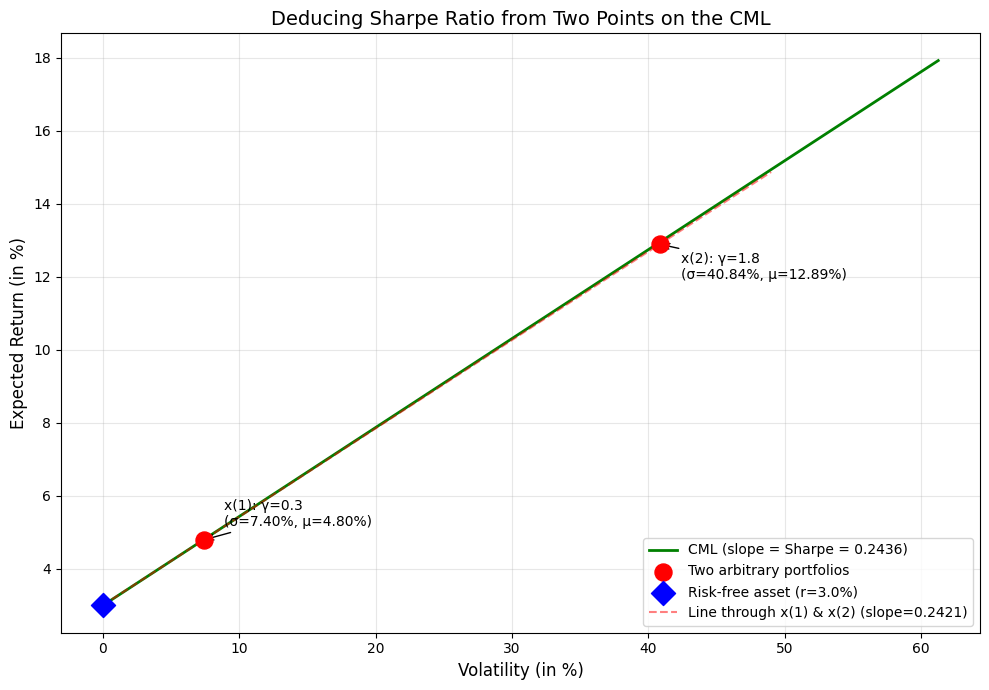

In [10]:
# ============================================================
# Question: Deduce Sharpe Ratio from Two Arbitrary Portfolios on the CML
# ============================================================
# Since the efficient frontier is the Capital Market Line (CML), a straight line:
#   mu_p = r + Sharpe * sigma_p
# Any two distinct points (sigma_1, mu_1) and (sigma_2, mu_2) on this line
# determine the slope, which equals the Sharpe ratio of the tangency portfolio.

# --- Step 1: Pick two arbitrary gamma values and solve the QP ---
# We deliberately pick values that are NOT the tangency portfolio itself
gamma_a = 0.3
gamma_b = 1.8

x_tilde_a = solve_augmented_qp(gamma_a)
x_tilde_b = solve_augmented_qp(gamma_b)

# Compute (sigma, mu) for both portfolios
sigma_a = np.sqrt(x_tilde_a @ Sigma_tilde @ x_tilde_a)
mu_a = x_tilde_a @ mu_tilde
sigma_b = np.sqrt(x_tilde_b @ Sigma_tilde @ x_tilde_b)
mu_b = x_tilde_b @ mu_tilde

# --- Step 2: Deduce the Sharpe ratio from the slope of the line ---
# The CML equation: mu = r + Sharpe * sigma
# => Sharpe = (mu_a - r) / sigma_a   (using point a alone, if on the CML)
# But more robustly, using two points:
#   slope = (mu_b - mu_a) / (sigma_b - sigma_a)
# This slope IS the Sharpe ratio of the tangency portfolio.

sharpe_from_two_points = (mu_b - mu_a) / (sigma_b - sigma_a)

# Cross-check using a single point (should match if the point is exactly on CML)
sharpe_from_a = (mu_a - r) / sigma_a
sharpe_from_b = (mu_b - r) / sigma_b

# --- Step 3: Compare with the analytical Sharpe ratio ---
sharpe_analytical = sharpe_tangency  # Computed in the previous question

# --- Print the results ---
print("=" * 80)
print("Deducing Sharpe Ratio from Two Arbitrary Portfolios on the CML")
print("=" * 80)

print(f"\nPortfolio x(1) [gamma = {gamma_a}]:")
print(f"  Weights (risky): {np.round(x_tilde_a[:4]*100, 2)}%")
print(f"  Weight (rf):     {x_tilde_a[4]*100:7.2f}%")
print(f"  Volatility:      {sigma_a*100:7.2f}%")
print(f"  Expected return: {mu_a*100:7.2f}%")

print(f"\nPortfolio x(2) [gamma = {gamma_b}]:")
print(f"  Weights (risky): {np.round(x_tilde_b[:4]*100, 2)}%")
print(f"  Weight (rf):     {x_tilde_b[4]*100:7.2f}%")
print(f"  Volatility:      {sigma_b*100:7.2f}%")
print(f"  Expected return: {mu_b*100:7.2f}%")

print("\n" + "-" * 80)
print("Sharpe Ratio Estimation:")
print("-" * 80)
print(f"  Method 1: Slope from two points  = (mu_b - mu_a) / (sigma_b - sigma_a)")
print(f"           = ({mu_b*100:.2f}% - {mu_a*100:.2f}%) / ({sigma_b*100:.2f}% - {sigma_a*100:.2f}%)")
print(f"           = {sharpe_from_two_points:.6f}")
print(f"\n  Method 2: From point x(1) alone   = (mu_a - r) / sigma_a")
print(f"           = ({mu_a*100:.2f}% - {r*100:.2f}%) / {sigma_a*100:.2f}%")
print(f"           = {sharpe_from_a:.6f}")
print(f"\n  Method 3: From point x(2) alone   = (mu_b - r) / sigma_b")
print(f"           = ({mu_b*100:.2f}% - {r*100:.2f}%) / {sigma_b*100:.2f}%")
print(f"           = {sharpe_from_b:.6f}")
print(f"\n  Analytical (ground truth)         = sqrt(delta^T Sigma^{-1} delta)")
print(f"           = {sharpe_analytical:.6f}")
print("-" * 80)

# --- Visualize on a plot ---
plt.figure(figsize=(10, 7))

# Plot the analytical CML
cml_vols = np.linspace(0, max(sigma_a, sigma_b) * 1.5, 100)
cml_returns = r + sharpe_analytical * cml_vols
plt.plot(cml_vols*100, cml_returns*100, 'g-', linewidth=2,
         label=f'CML (slope = Sharpe = {sharpe_analytical:.4f})')

# Plot the two arbitrary portfolios
plt.scatter([sigma_a*100, sigma_b*100], [mu_a*100, mu_b*100],
            color='red', s=150, zorder=6, label='Two arbitrary portfolios')

plt.annotate(f'x(1): γ={gamma_a}\n(σ={sigma_a*100:.2f}%, μ={mu_a*100:.2f}%)',
             (sigma_a*100, mu_a*100), textcoords="offset points",
             xytext=(15, 10), fontsize=10,
             arrowprops=dict(arrowstyle='->', color='black'))

plt.annotate(f'x(2): γ={gamma_b}\n(σ={sigma_b*100:.2f}%, μ={mu_b*100:.2f}%)',
             (sigma_b*100, mu_b*100), textcoords="offset points",
             xytext=(15, -25), fontsize=10,
             arrowprops=dict(arrowstyle='->', color='black'))

# Plot the risk-free asset
plt.scatter(0, r*100, color='blue', s=150, marker='D', zorder=6,
            label=f'Risk-free asset (r={r*100:.1f}%)')

# Draw the line connecting the two points (should overlap with CML)
x_line = np.linspace(0, max(sigma_a, sigma_b) * 1.2, 50)
y_line = mu_a + sharpe_from_two_points * (x_line - sigma_a)
plt.plot(x_line*100, y_line*100, 'r--', alpha=0.5, linewidth=1.5,
         label=f'Line through x(1) & x(2) (slope={sharpe_from_two_points:.4f})')

# Formatting
plt.xlabel('Volatility (in %)', fontsize=12)
plt.ylabel('Expected Return (in %)', fontsize=12)
plt.title('Deducing Sharpe Ratio from Two Points on the CML', fontsize=14)
plt.legend(loc='lower right', fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

6.e Calculate then the composition of the tangency portfolio from x(1) and x(2).

In [ ]:
# ============================================================
# Question: Deduce the Tangency Portfolio from Two Portfolios on the CML
# ============================================================
# Key Insight:
# On the CML, every portfolio is a combination of the risk-free asset
# and the tangency portfolio. The tangency portfolio is the UNIQUE point
# where the weight on the risk-free asset is exactly zero.
#
# Method: Find alpha such that x_tilde^(alpha) = (1-alpha)*x(1) + alpha*x(2)
#         has zero weight on the risk-free asset (index 4).

# --- Step 1: Extract the risk-free weights from x(1) and x(2) ---
w_rf_a = x_tilde_a[4]   # weight on risk-free asset in portfolio x(1)
w_rf_b = x_tilde_b[4]   # weight on risk-free asset in portfolio x(2)

# --- Step 2: Solve for alpha such that w_rf = 0 ---
# w_rf^(alpha) = (1 - alpha) * w_rf_a + alpha * w_rf_b = 0
# => w_rf_a - alpha * w_rf_a + alpha * w_rf_b = 0
# => alpha * (w_rf_b - w_rf_a) = -w_rf_a
# => alpha = w_rf_a / (w_rf_a - w_rf_b)
alpha_tan = w_rf_a / (w_rf_a - w_rf_b)

# --- Step 3: Construct the tangency portfolio as a linear combination ---
x_tangency_from_2pts = (1 - alpha_tan) * x_tilde_a + alpha_tan * x_tilde_b

# Extract the risky-asset weights (first 4 components) and normalize them
x_tan_risky = x_tangency_from_2pts[:4]

# Verify that the rf weight is zero (numerical tolerance)
w_rf_tan = x_tangency_from_2pts[4]

# --- Step 4: Compute the tangency portfolio metrics ---
sigma_tan_from_2pts = np.sqrt(x_tan_risky @ Sigma @ x_tan_risky)
mu_tan_from_2pts = mu @ x_tan_risky
sharpe_tan_from_2pts = (mu_tan_from_2pts - r) / sigma_tan_from_2pts

# --- Print the results ---
print("=" * 80)
print("Deducing the Tangency Portfolio from Two Points on the CML")
print("=" * 80)

print(f"\nStep 1: Risk-free weights in the two portfolios")
print(f"  x(1) [gamma={gamma_a}]:  w_rf = {w_rf_a*100:7.2f}%")
print(f"  x(2) [gamma={gamma_b}]:  w_rf = {w_rf_b*100:7.2f}%")

print(f"\nStep 2: Solve for alpha such that the rf weight = 0")
print(f"  alpha = w_rf_a / (w_rf_a - w_rf_b)")
print(f"        = {w_rf_a*100:.2f}% / ({w_rf_a*100:.2f}% - ({w_rf_b*100:.2f}%))")
print(f"        = {alpha_tan:.4f}")

print(f"\nStep 3: Construct tangency portfolio: x_tan = (1-alpha)*x(1) + alpha*x(2)")
print(f"  (1 - alpha) = {1-alpha_tan:.4f}")
print(f"  alpha       = {alpha_tan:.4f}")

print("\n" + "-" * 80)
print("Tangency Portfolio Composition (Deduced from Two Points)")
print("-" * 80)
print("Risky Asset Weights:")
for i in range(4):
    print(f"  x{i+1} = {x_tan_risky[i]*100:7.2f}%")
print(f"  Sum  = {np.sum(x_tan_risky)*100:7.2f}%  (should be 100%)")
print(f"\nRisk-free asset weight: {w_rf_tan*100:.6f}%  (should be ~0)")

print("\nTangency Portfolio Metrics:")
print(f"  Expected Return:  {mu_tan_from_2pts*100:7.2f}%")
print(f"  Volatility:       {sigma_tan_from_2pts*100:7.2f}%")
print(f"  Sharpe Ratio:     {sharpe_tan_from_2pts:.6f}")

# --- Compare with the analytical solution ---
print("\n" + "-" * 80)
print("Comparison with the Analytical Tangency Portfolio")
print("-" * 80)
print(f"{'':>20} | {'Deduced':>12} | {'Analytical':>12} | {'Difference':>12}")
print("-" * 80)
for i in range(4):
    diff = abs(x_tan_risky[i] - x_tangency[i])
    print(f"  x{i+1} (risky)        | {x_tan_risky[i]*100:10.2f}% | {x_tangency[i]*100:10.2f}% | {diff*100:10.4f}%")

diff_mu = abs(mu_tan_from_2pts - mu_tan)
diff_sigma = abs(sigma_tan_from_2pts - sigma_tan)
diff_sharpe = abs(sharpe_tan_from_2pts - sharpe_tangency)
print(f"  Expected Return (mu) | {mu_tan_from_2pts*100:10.2f}% | {mu_tan*100:10.2f}% | {diff_mu*100:10.4f}%")
print(f"  Volatility (sigma)   | {sigma_tan_from_2pts*100:10.2f}% | {sigma_tan*100:10.2f}% | {diff_sigma*100:10.4f}%")
print(f"  Sharpe Ratio         | {sharpe_tan_from_2pts:12.6f} | {sharpe_tangency:12.6f} | {diff_sharpe:12.6f}")
print("-" * 80)

# --- Visualize on the plot ---
plt.figure(figsize=(10, 7))

# Plot the CML
cml_vols_plot = np.linspace(0, max(sigma_a, sigma_b) * 1.5, 100)
cml_returns_plot = r + sharpe_tangency * cml_vols_plot
plt.plot(cml_vols_plot*100, cml_returns_plot*100, 'g-', linewidth=2,
         label=f'CML (slope = {sharpe_tangency:.4f})')

# Plot the two arbitrary portfolios
plt.scatter([sigma_a*100, sigma_b*100], [mu_a*100, mu_b*100],
            color='red', s=120, zorder=5, label=f'x(1) and x(2) (γ={gamma_a}, {gamma_b})')
plt.annotate(f'x(1): γ={gamma_a}\n(σ={sigma_a*100:.2f}%, μ={mu_a*100:.2f}%)',
             (sigma_a*100, mu_a*100), textcoords="offset points",
             xytext=(15, 10), fontsize=10)
plt.annotate(f'x(2): γ={gamma_b}\n(σ={sigma_b*100:.2f}%, μ={mu_b*100:.2f}%)',
             (sigma_b*100, mu_b*100), textcoords="offset points",
             xytext=(15, -25), fontsize=10)

# Plot the deduced tangency portfolio
plt.scatter(sigma_tan_from_2pts*100, mu_tan_from_2pts*100, color='purple',
            s=200, marker='*', zorder=6,
            label=f'Deduced Tangency (σ={sigma_tan_from_2pts*100:.2f}%, μ={mu_tan_from_2pts*100:.2f}%)')

# Plot the risk-free asset
plt.scatter(0, r*100, color='blue', s=120, marker='D', zorder=6,
            label=f'Risk-free asset (r={r*100:.1f}%)')

# Draw the line connecting the two points (extending to find the tangency)
x_line = np.linspace(0, sigma_tan_from_2pts*1.3, 50)
y_line = mu_a + sharpe_from_two_points * (x_line - sigma_a)
plt.plot(x_line*100, y_line*100, 'k--', alpha=0.4, linewidth=1.5,
         label='Line through x(1) & x(2)')

# Formatting
plt.xlabel('Volatility (in %)', fontsize=12)
plt.ylabel('Expected Return (in %)', fontsize=12)
plt.title('Deducing the Tangency Portfolio from Two Points on the CML',
          fontsize=13)
plt.legend(loc='lower right', fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()